In [4]:
import os, cv2, json, random, numpy as np, kagglehub
from pathlib import Path
from tqdm import tqdm
import kagglehub

# 1. Connexion à Kaggle
print("Authentification Kaggle...")
kagglehub.login() # ⚠️ Colle ton token KGAT_... quand demandé

# 2. Téléchargement
print("Téléchargement du dataset depuis Kaggle...")
path = kagglehub.dataset_download("anassiguedmi/moroccan-zellige")

# 3. Préparation (Resize et Masques)
exts = ('.jpg', '.jpeg', '.png', '.webp')
image_paths = [os.path.join(r, f) for r, d, files in os.walk(path) for f in files if f.lower().endswith(exts)]
random.seed(42)
random.shuffle(image_paths)

n = len(image_paths)
splits = {
    "train": image_paths[:int(0.70 * n)],
    "val": image_paths[int(0.70 * n):int(0.85 * n)],
    "test": image_paths[int(0.85 * n):]
}

SIZE = 128
OUT = Path("processed/128") # On crée le dossier "processed"
for split, plist in splits.items():
    out_dir = OUT / split / "images"
    out_dir.mkdir(parents=True, exist_ok=True)
    for p in tqdm(plist, desc=f"Resize {split}"):
        img = cv2.imread(p, cv2.IMREAD_COLOR)
        if img is not None:
            img = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(out_dir / (Path(p).stem + ".png")), img)

def square_mask(size, ratio, rng):
    area = int(ratio * size * size)
    side = int(np.sqrt(area))
    m = np.zeros((size, size), np.uint8)
    x, y = rng.integers(0, size - side + 1, 2)
    m[y:y+side, x:x+side] = 1
    return m

MASK_ROOT = Path("processed/masks")
for split, plist in splits.items():
    img_dir = OUT / split / "images"
    for r in [0.10, 0.20, 0.40]:
        out = MASK_ROOT / f"{split}_square_{int(r*100)}"
        out.mkdir(parents=True, exist_ok=True)
        rng = np.random.default_rng(42 + int(r*100))
        for p in tqdm(plist, desc=f"Mask {split} {int(r*100)}%"):
            stem = Path(p).stem
            if (img_dir / f"{stem}.png").exists():
                cv2.imwrite(str(out / f"{stem}.png"), square_mask(SIZE, r, rng) * 255)

print("✅ Données prêtes sur Colab ! Dossier 'processed' créé.")

# 4. Import PyTorch
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

Authentification Kaggle...


Téléchargement du dataset depuis Kaggle...


100%|██████████| 35.8M/35.8M [00:00<00:00, 132MB/s]

Extracting files...



Mask test 40%: 100%|██████████| 234/234 [00:00<00:00, 3446.50it/s]

✅ Données prêtes sur Colab ! Dossier 'processed' créé.
Appareil utilisé : cuda


Kaggle credentials set.
Kaggle credentials successfully validated.


In [5]:
import random
from torch.utils.data import Dataset, DataLoader

class InpaintingDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.img_paths = list(Path(img_dir).glob("*.png"))
        self.mask_dir = Path(mask_dir)
        self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

        # On choisit un masque au hasard parmi 10, 20, 40% pour que le GAN apprenne à gérer toutes les tailles
        ratio = random.choice(["10", "20", "40"])
        mask_path = self.mask_dir / f"train_square_{ratio}" / img_path.name
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        img_t = self.transform(img)
        mask_t = torch.from_numpy(mask).float() / 255.0
        mask_t = (mask_t > 0.5).float().unsqueeze(0)

        # L'image trouée qu'on donne en entrée au GAN
        img_masked = img_t * (1 - mask_t)

        return img_masked, mask_t, img_t

dataset = InpaintingDataset("processed/128/train/images", "processed/masks")
dataloader = DataLoader(dataset, batch_size=32, shuffle=True) # batch_size 32 pour aller plus vite
print(f"Dataset prêt : {len(dataset)} images d'entraînement.")

Dataset prêt : 586 images d'entraînement.


In [6]:
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(4, 64, 4, 2, 1), nn.LeakyReLU(0.2))
        self.enc2 = nn.Sequential(nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2))
        self.enc3 = nn.Sequential(nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2))

        self.dec1 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU())
        self.dec2 = nn.Sequential(nn.ConvTranspose2d(256, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU())
        self.dec3 = nn.Sequential(nn.ConvTranspose2d(128, 3, 4, 2, 1), nn.Sigmoid())

    def forward(self, x, mask):
        # Concaténation de l'image trouée et du masque
        inp = torch.cat([x, mask], dim=1)
        e1 = self.enc1(inp)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)

        d1 = self.dec1(e3)
        d2 = self.dec2(torch.cat([d1, e2], dim=1))
        out = self.dec3(torch.cat([d2, e1], dim=1))

        # On garde les pixels d'origine et on remplit juste le trou
        return x * (1 - mask) + out * mask

class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 1, 4, 1, 1), nn.Sigmoid()
        )
    def forward(self, x):
        return self.model(x)

print("Architecture du GAN prête !")

Architecture du GAN prête !


In [9]:
gen = Generator().to(device)
disc = Discriminator().to(device)

opt_gen = optim.Adam(gen.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_disc = optim.Adam(disc.parameters(), lr=0.0002, betas=(0.5, 0.999))

bce = nn.BCELoss()
l1 = nn.L1Loss()

EPOCHS = 50
for epoch in range(EPOCHS):
    loop = tqdm(dataloader, leave=True)
    for img_masked, mask, img_real in loop:
        img_masked, mask, img_real = img_masked.to(device), mask.to(device), img_real.to(device)

        # --- Entraînement du Générateur ---
        fake_img = gen(img_masked, mask)
        pred_fake = disc(fake_img)
        loss_g_adv = bce(pred_fake, torch.ones_like(pred_fake))
        loss_g_l1 = l1(fake_img, img_real) * 100 # L1 force la similarité avec l'original
        loss_g = loss_g_adv + loss_g_l1

        opt_gen.zero_grad()
        loss_g.backward()
        opt_gen.step()

        # --- Entraînement du Discriminateur ---
        pred_real = disc(img_real)
        loss_d_real = bce(pred_real, torch.ones_like(pred_real))

        pred_fake = disc(fake_img.detach())
        loss_d_fake = bce(pred_fake, torch.zeros_like(pred_fake))
        loss_d = (loss_d_real + loss_d_fake) / 2

        opt_disc.zero_grad()
        loss_d.backward()
        opt_disc.step()

        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss_G=loss_g.item(), loss_D=loss_d.item())

# Sauvegarde du modèle entraîné
torch.save(gen.state_dict(), "generator_weights.pth")
print("Entraînement terminé et modèle sauvegardé !")

Epoch [50/50]: 100%|██████████| 19/19 [00:02<00:00,  6.83it/s, loss_D=0.585, loss_G=5.71]

Entraînement terminé et modèle sauvegardé !


Évaluation sur le jeu de test...


100%|██████████| 191/191 [00:01<00:00, 131.18it/s]



--- RÉSULTATS GAN (Masque 20%) ---
PSNR moyen : 17.70
SSIM moyen : 0.800
(Rappel Baseline : PSNR = 18.39 | SSIM = 0.811)


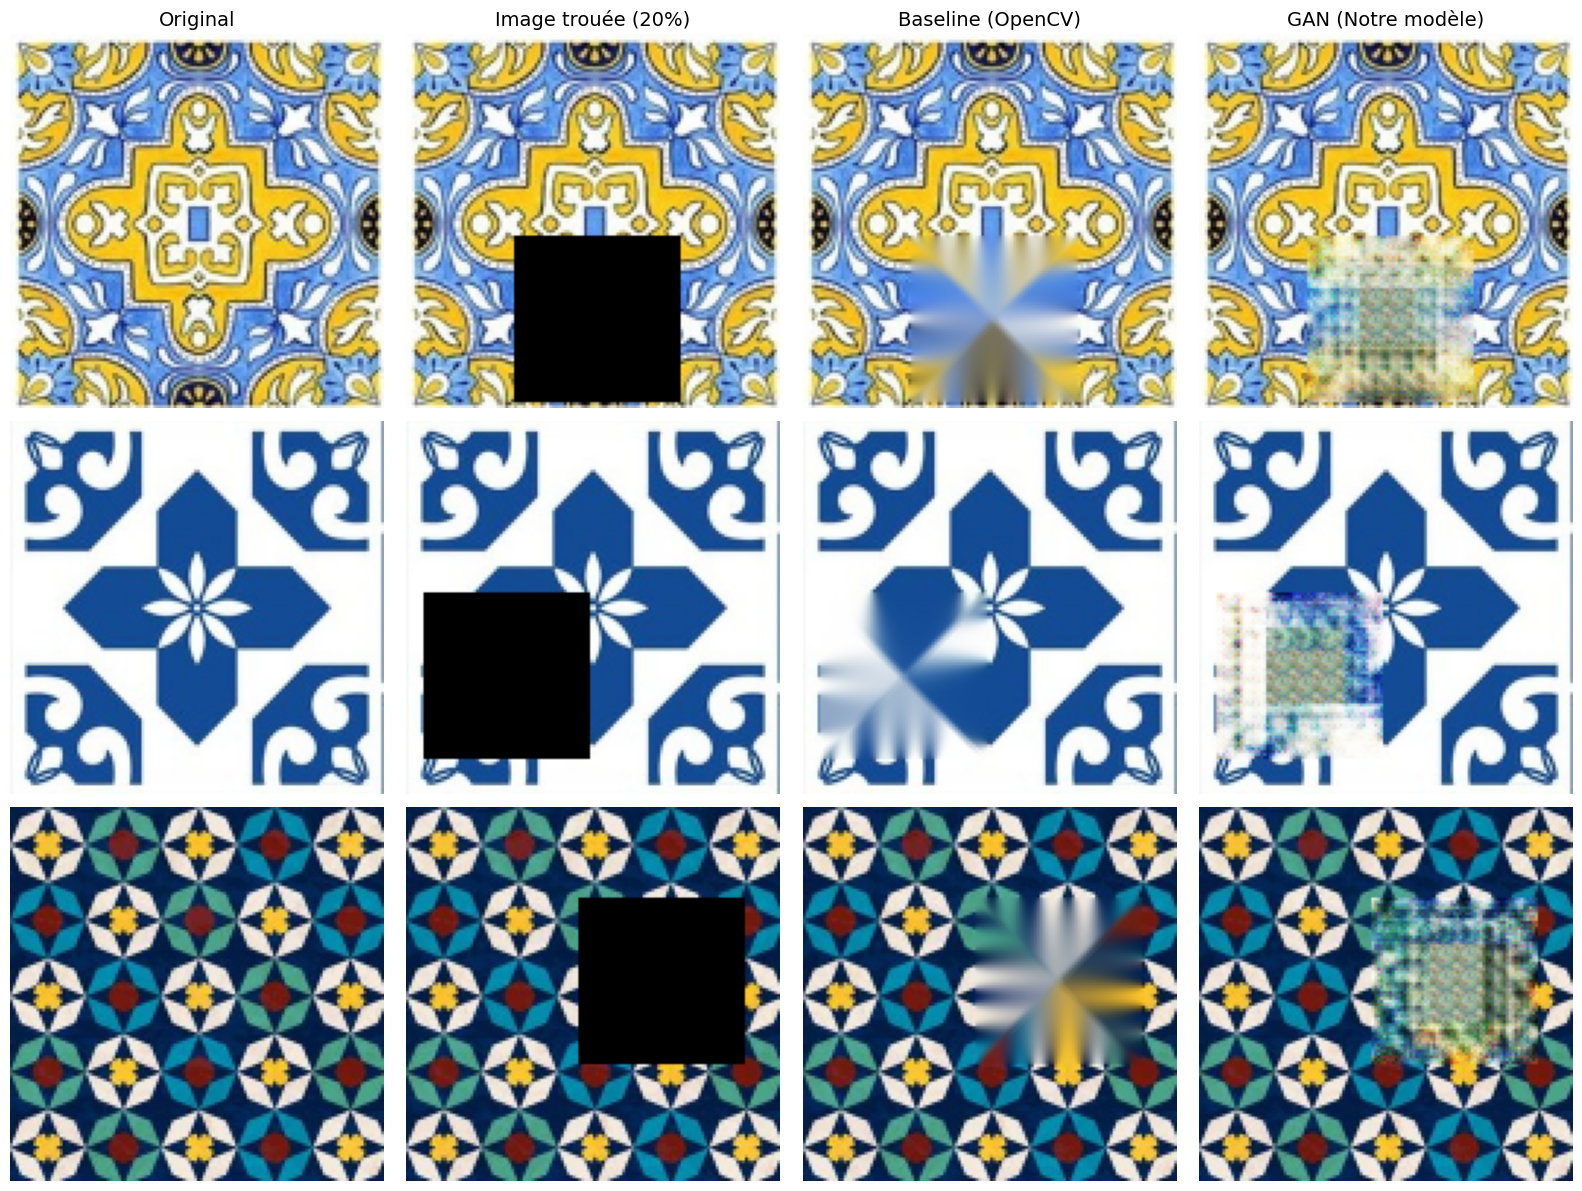

In [10]:
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# 1. Charger le modèle entraîné
gen.load_state_dict(torch.load("generator_weights.pth"))
gen.eval()

# 2. Calcul des métriques (sur le masque 20%)
psnr_vals, ssim_vals = [], []
test_paths = list(Path("processed/128/test/images").glob("*.png"))
mask_dir = Path("processed/masks/test_square_20")

print("Évaluation sur le jeu de test...")
with torch.no_grad():
    for p in tqdm(test_paths):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        img_t = transforms.ToTensor()(img).unsqueeze(0).to(device)

        mask = cv2.imread(str(mask_dir / p.name), cv2.IMREAD_GRAYSCALE)
        mask_t = torch.from_numpy(mask).float().to(device) / 255.0
        mask_t = (mask_t > 0.5).float().unsqueeze(0).unsqueeze(0)

        img_masked = img_t * (1 - mask_t)
        fake_img = gen(img_masked, mask_t)

        fake_np = (fake_img.squeeze(0).cpu().permute(1, 2, 0).numpy() * 255).astype(np.uint8)

        psnr_vals.append(psnr(img, fake_np, data_range=255))
        ssim_vals.append(ssim(img, fake_np, data_range=255, channel_axis=2))

print("\n--- RÉSULTATS GAN (Masque 20%) ---")
print(f"PSNR moyen : {np.mean(psnr_vals):.2f}")
print(f"SSIM moyen : {np.mean(ssim_vals):.3f}")
print("(Rappel Baseline : PSNR = 18.39 | SSIM = 0.811)")

# 3. Affichage visuel (Grille de 4 images)
# On prend 3 images au hasard pour le rapport
sample_paths = test_paths[:3]
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes[0,0].set_title("Original", fontsize=14)
axes[0,1].set_title("Image trouée (20%)", fontsize=14)
axes[0,2].set_title("Baseline (OpenCV)", fontsize=14)
axes[0,3].set_title("GAN (Notre modèle)", fontsize=14)

with torch.no_grad():
    for i, p in enumerate(sample_paths):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        img_t = transforms.ToTensor()(img).unsqueeze(0).to(device)

        mask = cv2.imread(str(mask_dir / p.name), cv2.IMREAD_GRAYSCALE)
        mask_t = torch.from_numpy(mask).float().to(device) / 255.0
        mask_t = (mask_t > 0.5).float().unsqueeze(0).unsqueeze(0)

        img_masked = img_t * (1 - mask_t)
        fake_img = gen(img_masked, mask_t)

        # Préparation des images pour matplotlib
        img_masked_np = img_masked.squeeze(0).cpu().permute(1, 2, 0).numpy()
        fake_np = fake_img.squeeze(0).cpu().permute(1, 2, 0).numpy()

        # OpenCV Baseline
        img_masked_cv = cv2.cvtColor((img_masked_np * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
        baseline_out = cv2.inpaint(img_masked_cv, mask, 3, cv2.INPAINT_TELEA)
        baseline_out = cv2.cvtColor(baseline_out, cv2.COLOR_BGR2RGB)

        # Affichage
        axes[i, 0].imshow(img); axes[i, 0].axis("off")
        axes[i, 1].imshow(img_masked_np); axes[i, 1].axis("off")
        axes[i, 2].imshow(baseline_out); axes[i, 2].axis("off")
        axes[i, 3].imshow(fake_np); axes[i, 3].axis("off")

plt.tight_layout()
plt.show()

In [11]:
import torch.nn.functional as F

class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost):
        super(VectorQuantizer, self).__init__()
        self.embedding = nn.Embedding(num_embeddings, embedding_dim)
        self.embedding.weight.data.uniform_(-1/num_embeddings, 1/num_embeddings)
        self.commitment_cost = commitment_cost

    def forward(self, inputs):
        # Convertir les entrées en (Batch, Seq, Dim)
        inputs = inputs.permute(0, 2, 3, 1).contiguous()
        input_shape = inputs.shape
        flat_input = inputs.view(-1, input_shape[-1])

        # Calculer les distances entre les entrées et les vecteurs du codebook
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True)
                    + torch.sum(self.embedding.weight**2, dim=1)
                    - 2 * torch.matmul(flat_input, self.embedding.weight.t()))

        # Trouver l'index le plus proche
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        encodings = torch.zeros(encoding_indices.shape[0], self.embedding.weight.shape[0], device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)

        # Quantifier
        quantized = torch.matmul(encodings, self.embedding.weight).view(input_shape)

        # Losses (Codebook + Commitment)
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)
        q_latent_loss = F.mse_loss(quantized, inputs.detach())
        loss = q_latent_loss + self.commitment_cost * e_latent_loss

        quantized = inputs + (quantized - inputs).detach() # Gradient trick
        avg_probs = torch.mean(encodings, dim=0)
        perplexity = torch.exp(-torch.sum(avg_probs * torch.log(avg_probs + 1e-10)))

        return quantized.permute(0, 3, 1, 2).contiguous(), loss, perplexity

class VQVAE(nn.Module):
    def __init__(self):
        super(VQVAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, 1, 1)
        )
        self.vq = VectorQuantizer(num_embeddings=512, embedding_dim=128, commitment_cost=0.25)
        self.decoder = nn.Sequential(
            nn.Conv2d(128, 128, 3, 1, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        quantized, loss, perplexity = self.vq(z)
        x_recon = self.decoder(quantized)
        return x_recon, loss, perplexity

vqvae = VQVAE().to(device)
opt_vq = optim.Adam(vqvae.parameters(), lr=0.001)

# Entraînement du VQ-VAE (10 époques suffisent pour un début)
print("Entraînement du VQ-VAE...")
for epoch in range(10):
    loop = tqdm(dataloader, leave=True)
    for img_masked, mask, img_real in loop:
        img_real = img_real.to(device)
        x_recon, vq_loss, perplexity = vqvae(img_real)
        recon_loss = F.mse_loss(x_recon, img_real)
        loss = recon_loss + vq_loss

        opt_vq.zero_grad()
        loss.backward()
        opt_vq.step()

        loop.set_description(f"VQ-VAE Epoch [{epoch+1}/10]")
        loop.set_postfix(loss=loss.item(), recon=recon_loss.item())

torch.save(vqvae.state_dict(), "vqvae_weights.pth")
print("VQ-VAE entraîné et sauvegardé !")

Entraînement du VQ-VAE...


VQ-VAE Epoch [10/10]: 100%|██████████| 19/19 [00:01<00:00, 12.78it/s, loss=0.0511, recon=0.0426]

VQ-VAE entraîné et sauvegardé !


In [13]:
import torch.nn.functional as F

print("Entraînement du PixelCNN (classification des codes VQ-VAE)...")
for epoch in range(5):
    loop = tqdm(dataloader, leave=True)
    for img_masked, mask, img_real in loop:
        img_real = img_real.to(device)

        with torch.no_grad():
            # 1. Obtenir les vecteurs quantifiés du VQ-VAE
            z = vqvae.encoder(img_real) # (B, 128, 32, 32)
            quantized, _, _ = vqvae.vq(z) # (B, 128, 32, 32)

            # 2. Extraire les indices discrets (la "vérité terrain" pour le PixelCNN)
            z_permuted = z.permute(0, 2, 3, 1).contiguous() # (B, 32, 32, 128)
            flat_z = z_permuted.view(-1, 128)
            distances = (torch.sum(flat_z**2, dim=1, keepdim=True)
                         + torch.sum(vqvae.vq.embedding.weight**2, dim=1)
                         - 2 * torch.matmul(flat_z, vqvae.vq.embedding.weight.t()))
            # On récupère l'index du code le plus proche (entre 0 et 511)
            target = torch.argmin(distances, dim=1).view(img_real.size(0), 32, 32) # (B, 32, 32)

        # 3. Le PixelCNN prédit la probabilité de chaque code (512 classes)
        pred = pixelcnn(quantized) # (B, 512, 32, 32)

        # 4. On utilise la CrossEntropy (très importante ici)
        loss = F.cross_entropy(pred, target)

        opt_pcnn.zero_grad()
        loss.backward()
        opt_pcnn.step()

        loop.set_description(f"PixelCNN Epoch [{epoch+1}/5]")
        loop.set_postfix(loss=loss.item())

torch.save(pixelcnn.state_dict(), "pixelcnn_weights.pth")
print("PixelCNN entraîné et sauvegardé avec succès !")

Entraînement du PixelCNN (classification des codes VQ-VAE)...


PixelCNN Epoch [5/5]: 100%|██████████| 19/19 [00:02<00:00,  8.88it/s, loss=2.09]

PixelCNN entraîné et sauvegardé avec succès !


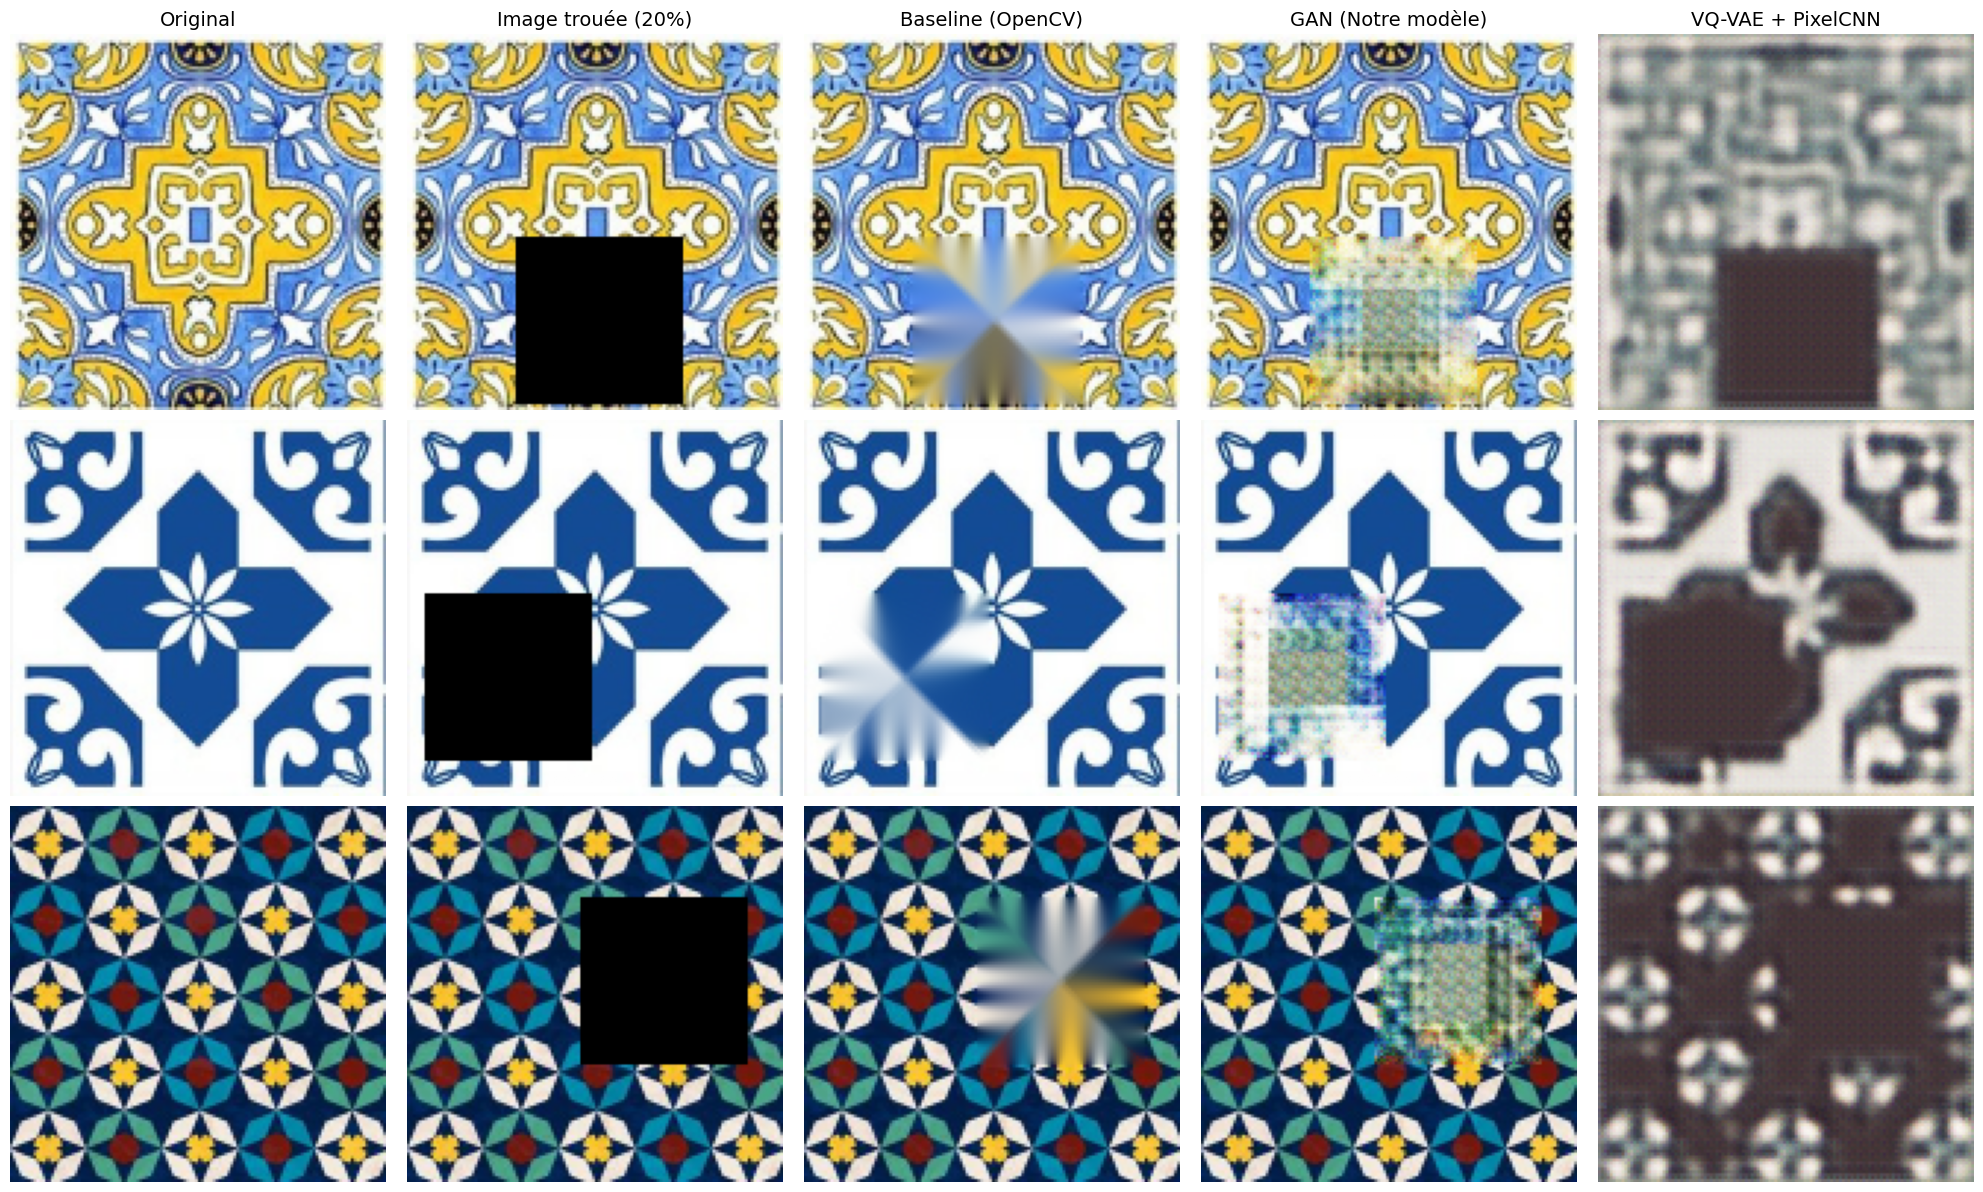


--- RÉSULTATS VQ-VAE + PixelCNN (Masque 20%) ---
PSNR moyen : 10.88
SSIM moyen : 0.317
(Rappel GAN : PSNR = 17.70 | Baseline = 18.39)


In [14]:
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# 1. Charger les modèles
gen.load_state_dict(torch.load("generator_weights.pth"))
vqvae.load_state_dict(torch.load("vqvae_weights.pth"))
pixelcnn.load_state_dict(torch.load("pixelcnn_weights.pth"))
gen.eval(); vqvae.eval(); pixelcnn.eval()

test_paths = list(Path("processed/128/test/images").glob("*.png"))
mask_dir = Path("processed/masks/test_square_20")

# On prend 3 images au hasard
sample_paths = test_paths[:3]
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes[0,0].set_title("Original", fontsize=14)
axes[0,1].set_title("Image trouée (20%)", fontsize=14)
axes[0,2].set_title("Baseline (OpenCV)", fontsize=14)
axes[0,3].set_title("GAN (Notre modèle)", fontsize=14)
axes[0,4].set_title("VQ-VAE + PixelCNN", fontsize=14)

psnr_vq, ssim_vq = [], []

with torch.no_grad():
    for i, p in enumerate(sample_paths):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        img_t = transforms.ToTensor()(img).unsqueeze(0).to(device)

        mask = cv2.imread(str(mask_dir / p.name), cv2.IMREAD_GRAYSCALE)
        mask_t = torch.from_numpy(mask).float().to(device) / 255.0
        mask_t = (mask_t > 0.5).float().unsqueeze(0).unsqueeze(0)

        img_masked = img_t * (1 - mask_t)

        # --- 1. Baseline OpenCV ---
        img_masked_cv = cv2.cvtColor((img_masked.squeeze(0).cpu().permute(1, 2, 0).numpy() * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
        baseline_out = cv2.inpaint(img_masked_cv, mask, 3, cv2.INPAINT_TELEA)
        baseline_out = cv2.cvtColor(baseline_out, cv2.COLOR_BGR2RGB)

        # --- 2. GAN ---
        fake_img = gen(img_masked, mask_t)
        fake_np = fake_img.squeeze(0).cpu().permute(1, 2, 0).numpy()

        # --- 3. VQ-VAE + PixelCNN ---
        # a) Obtenir les codes de l'image originale (pour garder le contour)
        z_real = vqvae.encoder(img_t)
        z_real_p = z_real.permute(0, 2, 3, 1).contiguous()
        flat_real = z_real_p.view(-1, 128)
        dist_real = torch.sum(flat_real**2, 1, keepdim=True) + torch.sum(vqvae.vq.embedding.weight**2, 1) - 2 * torch.matmul(flat_real, vqvae.vq.embedding.weight.t())
        idx_real = torch.argmin(dist_real, 1).view(1, 32, 32)

        # b) Prédire les codes manquants avec le PixelCNN
        z_masked = vqvae.encoder(img_masked)
        quantized_masked, _, _ = vqvae.vq(z_masked)
        pred_logits = pixelcnn(quantized_masked)
        idx_pred = torch.argmax(pred_logits, dim=1)

        # c) Fusionner les codes (on garde les codes réels là où il n'y a pas de trou)
        mask_32 = F.interpolate(mask_t, size=(32, 32), mode='nearest').squeeze(1).long()
        idx_final = idx_real * (1 - mask_32) + idx_pred * mask_32

        # d) Décoder le résultat
        emb_final = vqvae.vq.embedding(idx_final).permute(0, 3, 1, 2).contiguous()
        vq_recon = vqvae.decoder(emb_final)
        vq_np = vq_recon.squeeze(0).cpu().permute(1, 2, 0).numpy()

        # Calcul des métriques VQ-VAE
        vq_uint8 = (vq_np * 255).astype(np.uint8)
        psnr_vq.append(psnr(img, vq_uint8, data_range=255))
        ssim_vq.append(ssim(img, vq_uint8, data_range=255, channel_axis=2))

        # Affichage
        axes[i, 0].imshow(img); axes[i, 0].axis("off")
        axes[i, 1].imshow(img_masked.squeeze(0).cpu().permute(1, 2, 0).numpy()); axes[i, 1].axis("off")
        axes[i, 2].imshow(baseline_out); axes[i, 2].axis("off")
        axes[i, 3].imshow(fake_np); axes[i, 3].axis("off")
        axes[i, 4].imshow(vq_np); axes[i, 4].axis("off")

plt.tight_layout()
plt.show()

print(f"\n--- RÉSULTATS VQ-VAE + PixelCNN (Masque 20%) ---")
print(f"PSNR moyen : {np.mean(psnr_vq):.2f}")
print(f"SSIM moyen : {np.mean(ssim_vq):.3f}")
print("(Rappel GAN : PSNR = 17.70 | Baseline = 18.39)")

In [15]:
!pip install -q gradio
import gradio as gr
from PIL import Image

def inpaint_demo(input_image, mask_ratio):
    if input_image is None:
        return None

    # 1. Préparer l'image
    img = cv2.cvtColor(np.array(input_image), cv2.COLOR_RGB2BGR)
    img = cv2.resize(img, (128, 128))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_t = transforms.ToTensor()(img_rgb).unsqueeze(0).to(device)

    # 2. Créer un masque carré au centre (selon le slider)
    ratio = int(mask_ratio) / 100.0
    side = int(np.sqrt(ratio * 128 * 128))
    mask = np.zeros((128, 128), dtype=np.uint8)
    start = (128 - side) // 2
    mask[start:start+side, start:start+side] = 255

    mask_t = torch.from_numpy(mask).float().to(device) / 255.0
    mask_t = (mask_t > 0.5).float().unsqueeze(0).unsqueeze(0)

    # 3. Appliquer le GAN
    img_masked = img_t * (1 - mask_t)
    with torch.no_grad():
        fake_img = gen(img_masked, mask_t)

    # 4. Formater la sortie
    out_np = (fake_img.squeeze(0).cpu().permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    return Image.fromarray(out_np)

# Création de l'interface
demo = gr.Interface(
    fn=inpaint_demo,
    inputs=[
        gr.Image(label="Charge une image de zellige"),
        gr.Slider(minimum=10, maximum=40, value=20, step=10, label="Taille du trou (%)")
    ],
    outputs=gr.Image(label="Image restaurée par le GAN"),
    title="🕌 Restauration de Zellige par GAN",
    description="Chargez une image, choisissez la taille de la zone manquante, et l'IA la complétera !"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8782d23f41c7732e3c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [16]:
import torchvision.models as models

# 1. Charger VGG16 (pré-entraîné sur ImageNet)
vgg = models.vgg16(pretrained=True).features[:16].to(device).eval()
for param in vgg.parameters():
    param.requires_grad = False

def perceptual_loss(fake, real):
    # VGG attend des images normalisées, on s'assure que c'est bon
    fake_features = vgg(fake)
    real_features = vgg(real)
    return F.mse_loss(fake_features, real_features)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 74.0MB/s]


In [17]:
# Réinitialiser le générateur et l'optimiseur
gen = Generator().to(device)
opt_gen = optim.Adam(gen.parameters(), lr=0.0002, betas=(0.5, 0.999))
disc = Discriminator().to(device)
opt_disc = optim.Adam(disc.parameters(), lr=0.0002, betas=(0.5, 0.999))

EPOCHS = 30  # Plus long pour bien converger
for epoch in range(EPOCHS):
    loop = tqdm(dataloader, leave=True)
    for img_masked, mask, img_real in loop:
        img_masked, mask, img_real = img_masked.to(device), mask.to(device), img_real.to(device)

        # --- Générateur ---
        fake_img = gen(img_masked, mask)
        pred_fake = disc(fake_img)

        # Les 3 pertes combinées :
        loss_g_adv = bce(pred_fake, torch.ones_like(pred_fake))
        loss_g_l1 = l1(fake_img, img_real) * 100
        loss_g_perc = perceptual_loss(fake_img, img_real) * 10 # NOUVEAU

        loss_g = loss_g_adv + loss_g_l1 + loss_g_perc

        opt_gen.zero_grad()
        loss_g.backward()
        opt_gen.step()

        # --- Discriminateur (inchangé) ---
        pred_real = disc(img_real)
        loss_d_real = bce(pred_real, torch.ones_like(pred_real))
        pred_fake = disc(fake_img.detach())
        loss_d_fake = bce(pred_fake, torch.zeros_like(pred_fake))
        loss_d = (loss_d_real + loss_d_fake) / 2

        opt_disc.zero_grad()
        loss_d.backward()
        opt_disc.step()

        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss_G=loss_g.item(), loss_D=loss_d.item())

# Sauvegarder le nouveau modèle
torch.save(gen.state_dict(), "generator_v2_perceptual.pth")
print("Entraînement avec Perceptual Loss terminé !")

Epoch [30/30]: 100%|██████████| 19/19 [00:04<00:00,  3.90it/s, loss_D=0.529, loss_G=23.9]

Entraînement avec Perceptual Loss terminé !


In [20]:
import torchvision.models as models
import torch.nn.functional as F

vgg = models.vgg16(pretrained=True).features[:16].to(device).eval()
for param in vgg.parameters():
    param.requires_grad = False

# Les moyennes et écarts-types standards d'ImageNet pour VGG
vgg_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
vgg_std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

def perceptual_loss(fake, real):
    # 1. On normalise les images avant de les donner à VGG
    fake_norm = (fake - vgg_mean) / vgg_std
    real_norm = (real - vgg_mean) / vgg_std

    # 2. On extrait les features
    fake_features = vgg(fake_norm)
    real_features = vgg(real_norm)

    return F.mse_loss(fake_features, real_features)

In [21]:
# Réinitialiser le générateur
gen = Generator().to(device)
opt_gen = optim.Adam(gen.parameters(), lr=0.0002, betas=(0.5, 0.999))
disc = Discriminator().to(device)
opt_disc = optim.Adam(disc.parameters(), lr=0.0002, betas=(0.5, 0.999))

EPOCHS = 30
for epoch in range(EPOCHS):
    loop = tqdm(dataloader, leave=True)
    for img_masked, mask, img_real in loop:
        img_masked, mask, img_real = img_masked.to(device), mask.to(device), img_real.to(device)

        # --- Générateur ---
        fake_img = gen(img_masked, mask)
        pred_fake = disc(fake_img)

        loss_g_adv = bce(pred_fake, torch.ones_like(pred_fake))
        loss_g_l1 = l1(fake_img, img_real) * 100
        loss_g_perc = perceptual_loss(fake_img, img_real) * 1 # <-- POIDS RÉDUIT À 1

        loss_g = loss_g_adv + loss_g_l1 + loss_g_perc

        opt_gen.zero_grad()
        loss_g.backward()
        opt_gen.step()

        # --- Discriminateur ---
        pred_real = disc(img_real)
        loss_d_real = bce(pred_real, torch.ones_like(pred_real))
        pred_fake = disc(fake_img.detach())
        loss_d_fake = bce(pred_fake, torch.zeros_like(pred_fake))
        loss_d = (loss_d_real + loss_d_fake) / 2

        opt_disc.zero_grad()
        loss_d.backward()
        opt_disc.step()

        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss_G=loss_g.item(), loss_D=loss_d.item())

# Sauvegarder la version corrigée
torch.save(gen.state_dict(), "generator_v3_pro.pth")
print("Entraînement v3 terminé !")

Epoch [30/30]: 100%|██████████| 19/19 [00:05<00:00,  3.77it/s, loss_D=0.53, loss_G=16.6]

Entraînement v3 terminé !


In [22]:
gen.load_state_dict(torch.load("generator_v3_pro.pth"))
gen.eval()

Generator(
  (enc1): Sequential(
    (0): Conv2d(4, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  )
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
  )
  (enc3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
  )
  (dec1): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (dec2): Sequential(
    (0): ConvTranspose2d(256, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(64, eps=

In [23]:
import torchvision.models as models
import torch.nn.functional as F

vgg = models.vgg16(pretrained=True).features[:16].to(device).eval()
for param in vgg.parameters():
    param.requires_grad = False

vgg_mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
vgg_std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

def perceptual_loss(fake, real):
    fake_norm = (fake - vgg_mean) / vgg_std
    real_norm = (real - vgg_mean) / vgg_std
    fake_features = vgg(fake_norm)
    real_features = vgg(real_norm)
    return F.mse_loss(fake_features, real_features)

print("Nouvelle fonction de perte prête !")

Nouvelle fonction de perte prête !


In [24]:
# On réinitialise le générateur pour repartir de zéro
gen = Generator().to(device)
opt_gen = optim.Adam(gen.parameters(), lr=0.0002, betas=(0.5, 0.999))
disc = Discriminator().to(device)
opt_disc = optim.Adam(disc.parameters(), lr=0.0002, betas=(0.5, 0.999))

EPOCHS = 30
for epoch in range(EPOCHS):
    loop = tqdm(dataloader, leave=True)
    for img_masked, mask, img_real in loop:
        img_masked, mask, img_real = img_masked.to(device), mask.to(device), img_real.to(device)

        # --- Générateur ---
        fake_img = gen(img_masked, mask)
        pred_fake = disc(fake_img)

        loss_g_adv = bce(pred_fake, torch.ones_like(pred_fake))
        loss_g_l1 = l1(fake_img, img_real) * 100
        loss_g_perc = perceptual_loss(fake_img, img_real) * 1 # Poids réduit à 1

        loss_g = loss_g_adv + loss_g_l1 + loss_g_perc

        opt_gen.zero_grad()
        loss_g.backward()
        opt_gen.step()

        # --- Discriminateur ---
        pred_real = disc(img_real)
        loss_d_real = bce(pred_real, torch.ones_like(pred_real))
        pred_fake = disc(fake_img.detach())
        loss_d_fake = bce(pred_fake, torch.zeros_like(pred_fake))
        loss_d = (loss_d_real + loss_d_fake) / 2

        opt_disc.zero_grad()
        loss_d.backward()
        opt_disc.step()

        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss_G=loss_g.item(), loss_D=loss_d.item())

torch.save(gen.state_dict(), "generator_v3_pro.pth")
print("Entraînement v3 terminé !")

Epoch [30/30]: 100%|██████████| 19/19 [00:04<00:00,  3.88it/s, loss_D=0.536, loss_G=16]

Entraînement v3 terminé !


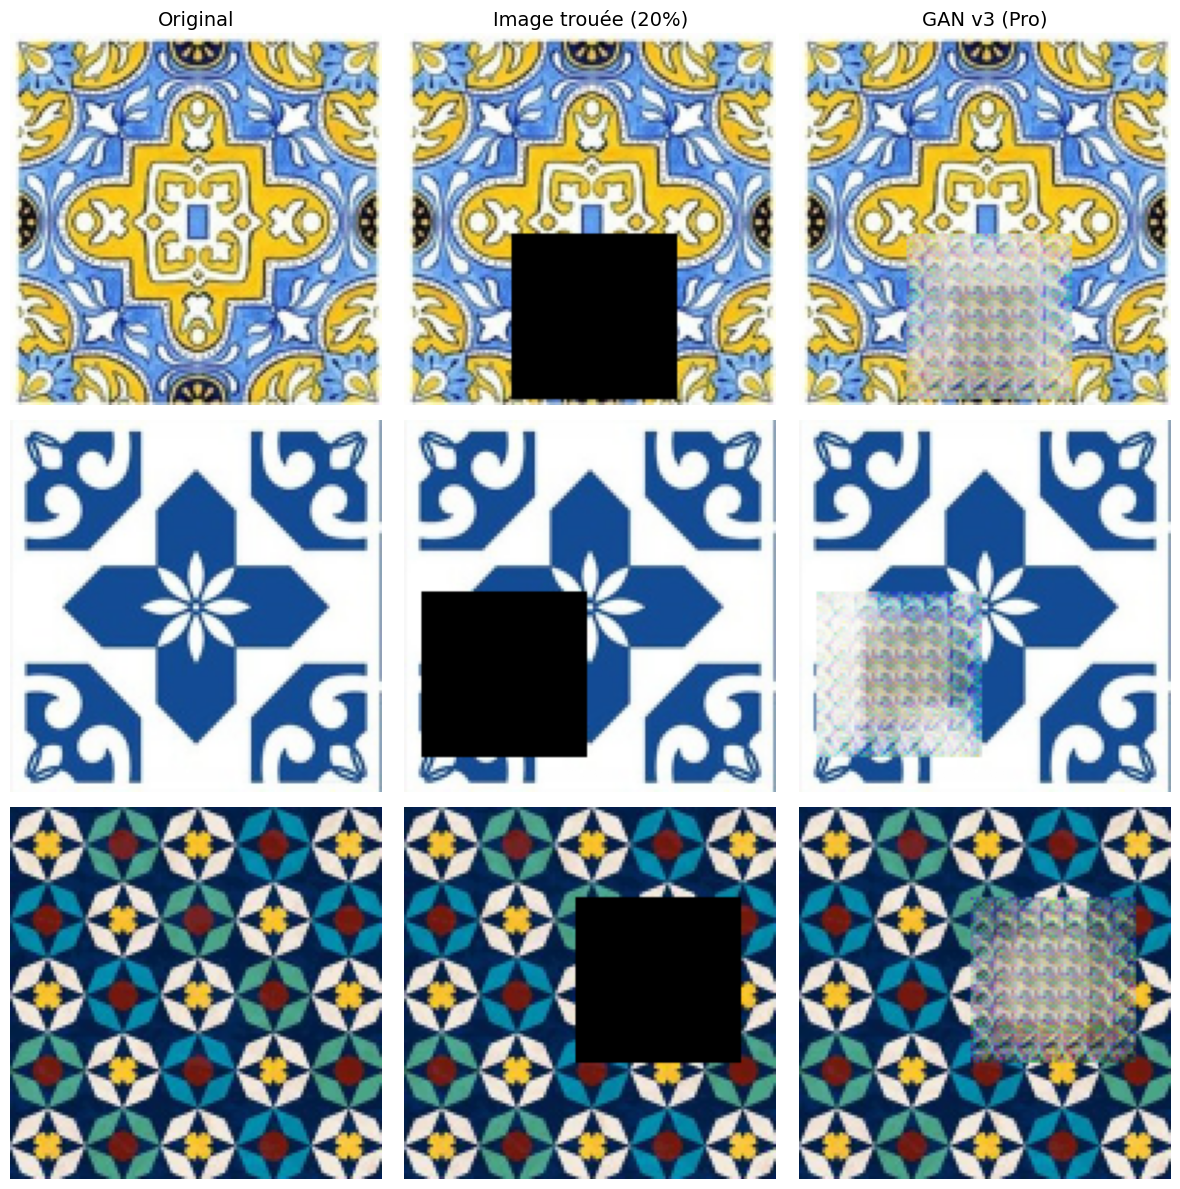

In [25]:
import matplotlib.pyplot as plt
from pathlib import Path
import cv2
import numpy as np
import torch

# On charge le modèle v3
gen.load_state_dict(torch.load("generator_v3_pro.pth"))
gen.eval()

test_paths = list(Path("processed/128/test/images").glob("*.png"))
mask_dir = Path("processed/masks/test_square_20")
sample_paths = test_paths[:3]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes[0,0].set_title("Original", fontsize=14)
axes[0,1].set_title("Image trouée (20%)", fontsize=14)
axes[0,2].set_title("GAN v3 (Pro)", fontsize=14)

with torch.no_grad():
    for i, p in enumerate(sample_paths):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        img_t = transforms.ToTensor()(img).unsqueeze(0).to(device)

        mask = cv2.imread(str(mask_dir / p.name), cv2.IMREAD_GRAYSCALE)
        mask_t = torch.from_numpy(mask).float().to(device) / 255.0
        mask_t = (mask_t > 0.5).float().unsqueeze(0).unsqueeze(0)

        img_masked = img_t * (1 - mask_t)
        fake_img = gen(img_masked, mask_t)

        axes[i, 0].imshow(img); axes[i, 0].axis("off")
        axes[i, 1].imshow(img_masked.squeeze(0).cpu().permute(1, 2, 0).numpy()); axes[i, 1].axis("off")
        axes[i, 2].imshow(fake_img.squeeze(0).cpu().permute(1, 2, 0).numpy()); axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

Chargement de Stable Diffusion Inpainting...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Génération de l'image en cours...


  0%|          | 0/30 [00:00<?, ?it/s]

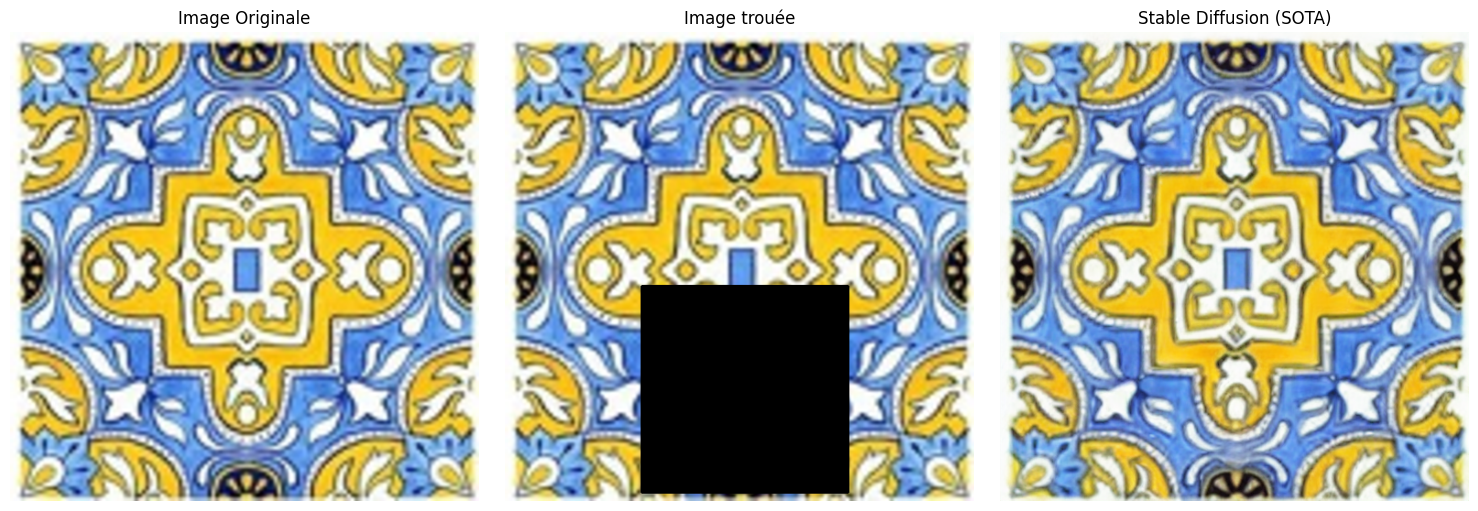

In [26]:
!pip install -q diffusers transformers accelerate

import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Chargement du modèle SOTA (prend ~1 min)
print("Chargement de Stable Diffusion Inpainting...")
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16,
).to(device)

# 2. Préparation de l'image et du masque (format 512x512)
test_paths = list(Path("processed/128/test/images").glob("*.png"))
img_original = Image.open(test_paths[0]).resize((512, 512))
mask_path = Path("processed/masks/test_square_20") / test_paths[0].name
mask_img = Image.open(mask_path).resize((512, 512)).convert("L")

# 3. Génération avec un prompt (c'est la magie des modèles de diffusion)
prompt = "Moroccan zellige tile pattern, intricate geometric design, blue and yellow colors, high quality"
print("Génération de l'image en cours...")
result = pipe(
    prompt=prompt,
    image=img_original,
    mask_image=mask_img,
    num_inference_steps=30
).images[0]

# 4. Affichage comparatif
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_original); axes[0].set_title("Image Originale")
axes[0].axis("off")

# On affiche le masque par-dessus l'image
mask_np = np.array(mask_img)
img_with_mask = np.array(img_original).copy()
img_with_mask[mask_np > 127] = 0 # Zone noire
axes[1].imshow(img_with_mask); axes[1].set_title("Image trouée")
axes[1].axis("off")

axes[2].imshow(result); axes[2].set_title("Stable Diffusion (SOTA)")
axes[2].axis("off")
plt.tight_layout()
plt.show()